## Imports

In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
from scipy.stats import f_oneway, ttest_ind #(not in environment yet?)

## Loading Data
Loading one single datafile using pandas, concatenatin all data files into one big table to analyse together

In [3]:
# works without this code apparently

#folder_path = "/Users/antoniabielefeldt1/Documents/MaxPlanck/MultiEyeTem/Analysis/MultiEyeTem_Repo/data/behavdata"
#folder_path = "/AMD/Data/AMDstudies/MultiEyeTem/behavioural_outputfiles/resultfile_pil05.txt"
#data = pd.read_table(folder_path)
#data = pd.read_table(folder_path + "/" + 'resultfile_pil05.txt')
#df = pd.DataFrame(data)
#print first 10 rows of the data (if left empty it prints the first 5 by default)





## Looping over all datafiles and concatenating them

In [4]:
# how can I concatenate all files within a certain folder path without loading a single file first

folder_path = "/Users/antoniabielefeldt1/Documents/MaxPlanck/MultiEyeTem/Analysis/MultiEyeTem_Repo/data/behavdata"

df = []
for file_name in os.listdir(folder_path):
    file_path = os.path.join(folder_path, file_name)
    files = pd.read_table(file_path, skipinitialspace = True)
    df.append(files)

df = pd.concat(df, ignore_index=True)
pd.DataFrame.describe(df)

,sub_age,block_number,trial,object_1_id,object_1_rot,object_2_id,object_2_rot,object_3_id,object_3_rot,retro_cue,...,righthanded,delay_1_null,delay_2_null,object_null_1,object_null_2,object_null_3,block_repe_null,items_presented,threshold_fix,eyes_alarm_on_off
count,1585.000000,1585.000000,1585.000000,1585.000000,1585.000000,1059.000000,1059.000000,528.000000,528.000000,1585.000000,...,1585.0,1585.000000,1585.0,1585.000000,1059.000000,528.000000,1585.0,1585.000000,1585.0,1152.0
mean,25.002524,7.957729,268.967192,2.000000,179.595426,1.999056,178.332153,1.994318,178.125000,1.505994,...,1.0,0.196215,0.0,0.036593,0.050992,0.037879,0.0,2.001262,70.5,1.0
std,2.765223,4.417465,159.355691,0.819584,103.361409,0.819769,103.397433,0.811426,104.152346,0.689108,...,0.0,0.397258,0.0,0.187820,0.220084,0.191084,0.0,0.815722,0.0,0.0
min,22.000000,1.000000,1.000000,1.000000,11.250000,1.000000,11.250000,1.000000,11.250000,1.000000,...,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,1.000000,70.5,1.0
25%,22.000000,4.000000,133.000000,1.000000,78.750000,1.000000,78.750000,1.000000,78.750000,1.000000,...,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,1.000000,70.5,1.0
50%,25.000000,8.000000,265.000000,2.000000,168.750000,2.000000,168.750000,2.000000,168.750000,1.000000,...,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,2.000000,70.5,1.0
75%,29.000000,12.000000,397.000000,3.000000,258.750000,3.000000,258.750000,3.000000,258.750000,2.000000,...,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,3.000000,70.5,1.0
max,29.000000,16.000000,576.000000,3.000000,348.750000,3.000000,348.750000,3.000000,348.750000,3.000000,...,1.0,1.000000,0.0,1.000000,1.000000,1.000000,0.0,3.000000,70.5,1.0


In [21]:
## Descriptive Statistics

# not sure if any of the following is actually helpful, df.describe probably is but seemed weird because not all columns were included
print(df.head(11))
pd.DataFrame.describe(df)
df_description = df.describe()
print(df_description)





## column names have a random space infront of the names; ' subID' instead of 'subID'
#dates = df. date

#value = 0
#df[df['righthanded'] >= value]
#df('sub_age').mean()
# df.sort_values(by='column_name', ascending=True)
# df.groupby(





              task_version         date   subID sub_gender  sub_age  \
0   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
1   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
2   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
3   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
4   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
5   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
6   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
7   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
8   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
9   MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   
10  MultiEyeTem_version_02  19-May-2023  XG7QAG          F       22   

    block_number  trial              object_1_name  object_1_id  object_1_rot  \
0              1      1  02_photoshopTelephone.jpg            3   

In [22]:
df.info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1585 entries, 0 to 1584
Data columns (total 53 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   task_version             1585 non-null   object 
 1   date                     1585 non-null   object 
 2   subID                    1585 non-null   object 
 3   sub_gender               1585 non-null   object 
 4   sub_age                  1585 non-null   int64  
 5   block_number             1585 non-null   int64  
 6   trial                    1585 non-null   int64  
 7   object_1_name            1585 non-null   object 
 8   object_1_id              1585 non-null   int64  
 9   object_1_rot             1585 non-null   float64
 10  object_2_name            1059 non-null   object 
 11  object_2_id              1059 non-null   float64
 12  object_2_rot             1059 non-null   float64
 13  object_3_name            528 non-null    object 
 14  object_3_id             

## Confidence / Manipulation Checks

In [ ]:
# check wether the mask makes a difference (would be a problem if it did)

# check wether condition makes it harder (it should)

# checking accuracy between upright and upside-down might also count as a manipulation check

# generally check if accuracy is good enough (when is it significantly above chance?)

## Accuracy Tests

In [ ]:
## Mask vs no Mask

# accuracy data mask
# there is no mask vs. no mask column yet, probably needs to be added individually

# mask_data = df.loc[df['XX'] == 1, 'acc_trial_concrete_cued']
# nomask_data = df.loc[df['XX'] == 1, 'acc_trial_concrete_cued']

# # Perform two-sample independent t-test
# t_statistic, p_value = ttest_ind(mask_data, nomask_data)

# # Define the significance level (alpha)
# alpha = 0.05

# # Print the t-test results
# print("T-Test Results:")
# print("T-statistic:", t_statistic)
# print("p-value:", p_value)

# # Check if the p-value is less than alpha to determine significance
# if p_value < alpha:
#     print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
# else:
#     print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")

In [37]:
## Mean accuracy by condition, oneway ANOVA
# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print(mean_cond)
mean_acc = df['acc_trial_concrete_cued'].mean()
print(mean_acc)


acc_cond1 = df.loc[df['items_presented'] == 1, 'acc_trial_concrete_cued']
acc_cond2 = df.loc[df['items_presented'] == 2, 'acc_trial_concrete_cued']
acc_cond3 = df.loc[df['items_presented'] == 3, 'acc_trial_concrete_cued']

# Perform one-way ANOVA
f_statistic, p_value = f_oneway(acc_cond1, acc_cond2, acc_cond3)

# Define the significance level (alpha)
alpha = 0.05

# Print the ANOVA results
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The one-way ANOVA indicates a significant difference among the three conditions.")
else:
    print("The one-way ANOVA does not indicate a significant difference among the three conditions.")




items_presented
1    0.798479
2    0.655367
3    0.600379
Name: acc_trial_concrete_cued, dtype: float64
0.6845425867507886
ANOVA Results:
F-statistic: 26.001786282471905
p-value: 7.748196847827994e-12
The one-way ANOVA indicates a significant difference among the three conditions.


In [6]:
## Upside down vs upright accuracy

# these give a boolean value (True/False)

#ud = (ud <= 270 and ud >= 90)
upside_down = (df['object_test_rot_cued'] < 270) & (df['object_test_rot_cued'] > 90)
upright = (df['object_test_rot_cued'] < 90) | (df['object_test_rot_cued'] > 270)
#upside_down = df['object_test_rot_cued'] ('object_test_rot_cued' <= 270) and ('object_test_rot_cued' >= 90)
# could probably do with only one variable and just check wether its true or false
# 180° is not the upright position necessarily, where does the circle start?
#upright = df['object_test_rot_cued'] == ud = (ud <= 270 and ud >= 90)

# might have to be upright= true or something

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)


# Perform two-sample independent t-test
t_statistic, p_value = ttest_ind(upside_down, upright)

# Define the significance level (alpha)
alpha = 0.05

# Print the t-test results
print("T-Test Results:")
print("T-statistic:", t_statistic)
print("p-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7012987012987013
0.6687116564417178
T-Test Results:
T-statistic: 1.5986409653268123
p-value: 0.1100001245125352
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


In [7]:
# Mnemonic distance + accuracy

block_number
1     0.666667
2     0.638889
3     0.685185
4     0.648148
5     0.601852
6     0.675926
7     0.675926
8     0.731481
9     0.694444
10    0.564815
11    0.768519
12    0.759259
13    0.767123
14    0.638889
15    0.777778
16    0.708333
Name: acc_trial_concrete_cued, dtype: float64


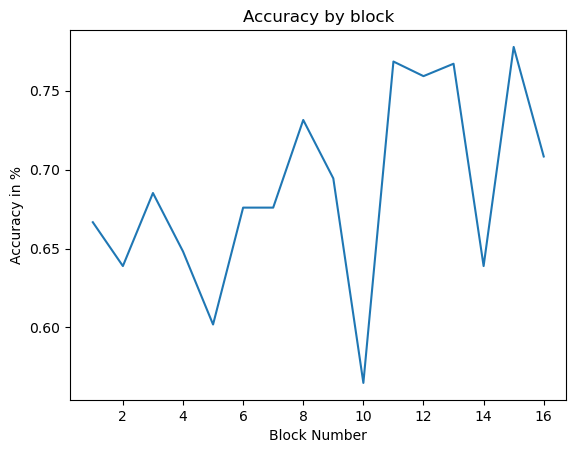

In [9]:
# Accuraccy over time (block by block, do they get better or worse)
# plots using matplotlib
# THIS DOES NOT SEEM TO WORK

#image = plt.imshow(mean_block_allp) #-> heatmap

# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
#df_sorted = df.sort_values(by='trial')
#print(df_sorted)
acc_by_block = plt.plot(mean_block_allp)
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot


## General Statistics

In [10]:
#Statistics??

# Calculate the standard deviation
#std_dev = df['column_name'].std()
# Calculate the standard deviation across the DataFrame
#std_dev = df.std()

## Circular Stuff

In [11]:
# # Make a column with 1 for clockwise and 0 for anticlockwise

# ### this gives me a column whose content is an object while I need it to be an integer to work on it??

# #if accuracy is True:
    
# #condition that would need to be true: wether the button press was clockwise or anticlockwise
# # if the rot of the tested item's orginal orienation minus the item's final test rotation is positive the accurate rotation would be anticlockwise

# df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']
# #what is the following line?
# df['button_press_clockwise'] = ''
# # Clockwise rotation = 1
# # if the correct response is clockwise and the person was correct -> clockwise button press
# df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# # if the correct response is clockwise and the person was not correct -> anticlockwise button press
# df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 0
# # if the correct response is anticlockwise and the person was correct -> anticlockwise button press
# df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 0
# # if the correct response is anticlockwise and the person was not correct -> clockwise button press
# df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

# # maybe need to make that new column into an integer column here, and not underneath when calculating the mean

# # Convert 'button_press_clockwise' to integer dtype
# df['button_press_clockwise'] = df['button_press_clockwise'].astype(int)

# print(df['button_press_clockwise'].dtype)


In [12]:
# The following code is  the same as the one above just simpler and without the need to convert the new column to integer at the end:

# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be able to ee in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed

## !! Still check if the actual column at the end is correct, then delete block above
# put these extra columns for the dataframe at the start to make it more easy to read?

# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

print(df['button_press_clockwise'].dtype)

columns = df.columns
column_names = df.columns.tolist()


int64


the mean of all button presses is: 0.47003154574132494
this is the mbp_per_con: items_presented
1    0.503802
2    0.463277
3    0.443182
Name: button_press_clockwise, dtype: float64
[0.46236559 0.46428571 0.2962963  0.27522936 0.40740741 0.44761905
 0.38888889 0.41414141 0.6952381  0.57575758 0.50549451 0.5
 0.73563218 0.57446809 0.55339806 0.2826087 ]


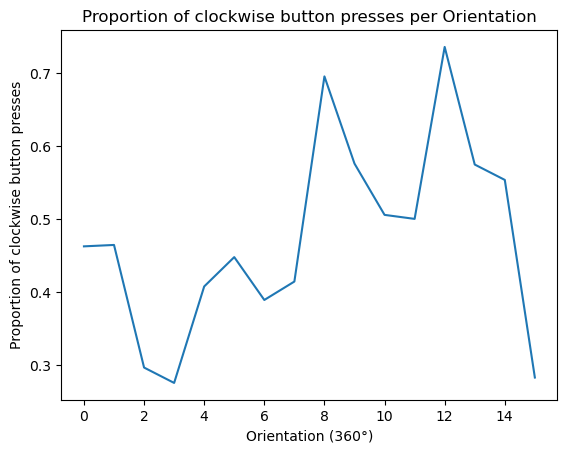

In [13]:
# mean clockwise proportion of all button presses
mean_button_press = df['button_press_clockwise'].mean()
print("the mean of all button presses is:", mean_button_press)

# mean button press per condition (do I already have that somewhere else?)
mbp_per_con = df.groupby('items_presented')['button_press_clockwise'].mean()
print("this is the mbp_per_con:", mbp_per_con)

# mean button press per rotation/ori
mean_rot_button_press = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
print(mean_rot_button_press)


# this is the same data as visualised in the polar plot and should probably be removed
plt.plot(mean_rot_button_press)

plt.xlabel('Orientation (360°)')  # Set the label for the x-axis
plt.ylabel('Proportion of clockwise button presses')  # Set the label for the y-axis
plt.title('Proportion of clockwise button presses per Orientation')  # Set the title for the plot
plt.show()  

## Code stops here when running all

For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

## Cardinal Repulsion Bias Plot (?)

spacing_rad1 [0.19634954 0.58904862 0.9817477  1.37444679 1.76714587 2.15984495
 2.55254403 2.94524311 3.33794219 3.73064128 4.12334036 4.51603944
 4.90873852 5.3014376  5.69413668 6.08683577]
spacing_rad2 [0.19634954 0.58904862 0.9817477  1.37444679 1.76714587 2.15984495
 2.55254403 2.94524311 3.33794219 3.73064128 4.12334036 4.51603944
 4.90873852 5.3014376  5.69413668 6.08683577 0.19634954]
[0.0080698  0.00810331 0.00517135 0.00480366 0.0071106  0.00781243
 0.00678739 0.00722813 0.01213419 0.01004887 0.00882254 0.00872665
 0.0128392  0.01002636 0.00965862 0.00493245]
MBP1: [0.4375, 0.5, 0.42424242424242425, 0.2647058823529412, 0.41935483870967744, 0.5483870967741935, 0.4411764705882353, 0.5483870967741935, 0.7647058823529411, 0.5142857142857142, 0.5483870967741935, 0.53125, 0.8064516129032258, 0.5555555555555556, 0.5428571428571428, 0.21875]
MBP2: [0.5185185185185185, 0.39285714285714285, 0.2972972972972973, 0.3783783783783784, 0.34210526315789475, 0.38235294117647056, 0.37837837837

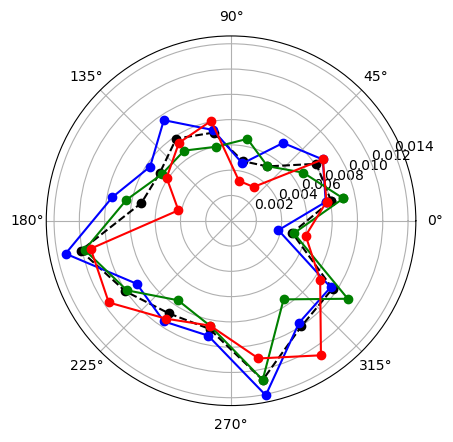

In [14]:


# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)
print("spacing_rad1", spacing_rad)
spacing_rad = np.append(spacing_rad, spacing_rad[0])
print("spacing_rad2", spacing_rad)

# mbp = mean button press
mbp_rad = np.radians(mean_rot_button_press)
print(mbp_rad)


# the following line returns the mean button press proportions for all three conditions -- need to somehow but them in individual 
# variables to then transform them into radians to then use them 

## !!!! This is wrong, I am using data at the moment that is a single data point while I actually need 16 data points 
# for every orientation (but also per condition per button press) -> I need data looking like mean_rot_button_press !!!!!!
# !!!!! use the code that I used to make mean_rot_button_press:


#### mean_button_press = df['button_press_clockwise'].mean()
#### print("the mean of all button presses is:", mean_button_press)

#### mean_rot_button_press = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
#### print(mean_rot_button_press)

# seperate object_cued_rot per condition first and then group the button press clockwise dependingly?

# this gives me the mean per condition, also interesting but I first need the button press mean per orientation?

# df.sort_values returns a new dataframe: that might be useful


mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].tolist()
mbp1_rad = np.radians(mbp1)
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].tolist()
mbp2_rad = np.radians(mbp2)
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].tolist()
mbp3_rad = np.radians(mbp3)

print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
mbp_rad = np.append(mbp_rad, mbp_rad[0])
mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

# Plot the data for the general mbp
ax.plot(spacing_rad, mbp_rad, 'ko--')

# Plot the data for the three conditions individually
ax.plot(spacing_rad, mbp1_rad, 'bo-')
ax.plot(spacing_rad, mbp2_rad, 'go-')
ax.plot(spacing_rad, mbp3_rad, 'ro-')

# Set plot attributes (-> labels and shit)

plt.legend
# Show the plot
plt.show()

## ANOVA for cardinal repulsion effect (?)

In [15]:
# This is probably not what I actually want 

# Perform one-way ANOVA
# The resulting data is every instance of the button_press_clockwise where "items_presented" is one
# however the three resulting variables are not the same size (length = 526, 531 & 528), Why?
# There are no NANs in the button presses (see above)
load_1_data = df[df['items_presented'] == 1]['button_press_clockwise']
load_2_data = df[df['items_presented'] == 2]['button_press_clockwise']
load_3_data = df[df['items_presented'] == 3]['button_press_clockwise']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = f_oneway(load_1_data, load_2_data, load_3_data)#



# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")



ANOVA Results:
F-statistic: 2.0180636548645485
p-value: 0.1332545992167208
The ANOVA test does not indicate a significant difference among the load conditions.
